# 03 GNN Models: GraphSAGE and GCN

This notebook trains GraphSAGE first and GCN second under the same graph, node features, balanced labelled subset, folds, hyperparameters, and five training seeds. The final section performs the paired GraphSAGE-versus-GCN comparison.

Run the notebook from top to bottom with a clean kernel. Core CSV files are exported for downstream analysis; tables and figures are also shown inline.

## Imports and dependencies

In [1]:
from IPython.display import display
import sys
import os

# See progress_summary.md Section 9 / the earlier GraphSAGE experiment for why this
# sys.exec_prefix patch is needed on this machine before `import torch`.
if not sys.exec_prefix.endswith(os.sep):
    sys.exec_prefix += os.sep
if not sys.base_exec_prefix.endswith(os.sep):
    sys.base_exec_prefix += os.sep

import json
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import SAGEConv, GCNConv

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import f1_score, balanced_accuracy_score
from scipy import stats

## 0. Setup -- Week 12, progress_summary.md Section 14.4/14.5

In [2]:
# Section 14.4 ran GraphSAGE and GCN with expanded (structural + transaction_
# behaviour) node features, but only at a single training seed (n=5 folds) --
# the same statistical-power gap flagged repeatedly elsewhere in this project
# (Sec 5.2/9.4/P3/methodology). This repeats that experiment across N_SEEDS
# distinct training seeds, exactly mirroring 04_message_passing_ablation.ipynb's
# design: SAME balanced subset, SAME fixed StratifiedKFold fold assignment
# across every (condition, seed) pair, only the training seed (weight init /
# dropout masks) varies. Seed-level means (averaged over the 5 folds within a
# seed) describe conditional training stability and avoid fold-level
# pseudo-replication. They are not independent address samples, fold
# assignments or graph snapshots and do not support population inference.

RANDOM_STATE = 42
N_SPLITS = 5
N_SEEDS = 5
TRAIN_SEEDS = [42, 43, 44, 45, 46]
LABEL_COL = "label"
LABEL_ORDER = ["CEX", "DeFi", "Malicious_MEV"]
HIDDEN_DIM = 16
DROPOUT = 0.6
WEIGHT_DECAY = 1e-3
LR = 0.01
MAX_EPOCHS = 300
PATIENCE = 20
VAL_FRACTION = 0.2

# Optional CLI args: edges_file balanced_subset_dir out_subdir node_feat_file.
_cwd = Path.cwd().resolve()
PROJECT_ROOT = next(
    (
        candidate
        for candidate in [_cwd, *_cwd.parents]
        if (candidate / "00_data_graph").exists()
        and (candidate / "04_supervised").exists()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run this notebook from the dissertation workspace.")
FEATURE_DIR = PROJECT_ROOT / "02_feature_engineering" / "feature_engineering"
EDGES_FILE = PROJECT_ROOT / "00_data_graph" / "data" / "main" / "raw_edges_reconstructed.csv"
BALANCED_DIR = PROJECT_ROOT / "06_robustness_audit" / "01_balanced_subset"
OUT_SUBDIR = PROJECT_ROOT / "04_supervised" / "02_gnn_models" / "graphsage_gcn_multiseed_results"
NODE_FEAT_FILE = FEATURE_DIR / "full_graph_transaction_behaviour_features.csv"
FEATURE_GROUPS_FILE = FEATURE_DIR / "feature_groups.json"

OUT_DIR = Path(OUT_SUBDIR)
OUT_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#0b0b0b", "text.color": "#0b0b0b", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "grid.color": "#e1e0d9", "font.size": 10,
})


def clean_address(x):
    if pd.isna(x):
        return np.nan
    return str(x).strip().lower()

## 1. Build the full graph

In [3]:
edges = pd.read_csv(EDGES_FILE)
edges["source"] = edges["source"].apply(clean_address)
edges["target"] = edges["target"].apply(clean_address)
edges = edges.dropna(subset=["source", "target"])

G_directed = nx.from_pandas_edgelist(edges, source="source", target="target", edge_attr=["tx_count"], create_using=nx.DiGraph())
G_undirected = G_directed.to_undirected()
for _, _, d in G_undirected.edges(data=True):
    d["weight"] = d.get("tx_count", 1)

print(f"Graph: {G_undirected.number_of_nodes()} nodes, {G_undirected.number_of_edges()} edges (undirected, message-passing view)")

Graph: 8029 nodes, 46953 edges (undirected, message-passing view)


## 2. Node features: structural + transaction_behaviour (28 cols, Section 14.2/14.3)

In [4]:
in_degree = dict(G_directed.in_degree())
out_degree = dict(G_directed.out_degree())
pagerank_rank = pd.Series(nx.pagerank(G_directed)).rank(pct=True)
pagerank_weighted_rank = pd.Series(nx.pagerank(G_directed, weight="tx_count")).rank(pct=True)
clustering = nx.clustering(G_undirected)
wcc_size = {}
for component in nx.weakly_connected_components(G_directed):
    size = len(component)
    for node in component:
        wcc_size[node] = size

nodes = list(G_undirected.nodes())
struct_df = pd.DataFrame({
    "in_degree": pd.Series(in_degree), "out_degree": pd.Series(out_degree),
    "pagerank_rank": pagerank_rank, "pagerank_weighted_rank": pagerank_weighted_rank,
    "clustering_coeff": pd.Series(clustering), "wcc_size": pd.Series(wcc_size),
}).reindex(nodes).fillna(0.0)
struct_df["degree"] = struct_df["in_degree"] + struct_df["out_degree"]
struct_df["log_degree"] = np.log1p(struct_df["degree"])
struct_df["has_closed_triangle"] = (struct_df["clustering_coeff"] > 0).astype(float)
struct_cols = ["in_degree", "out_degree", "degree", "pagerank_rank", "pagerank_weighted_rank",
               "clustering_coeff", "has_closed_triangle", "wcc_size", "log_degree"]
struct_df = struct_df[struct_cols]

with open(FEATURE_GROUPS_FILE) as f:
    txn_cols = json.load(f)["transaction_behaviour"]
txn_df = pd.read_csv(NODE_FEAT_FILE).set_index("address")[txn_cols].reindex(nodes).fillna(0.0)

combined_df = pd.concat([struct_df, txn_df], axis=1)
X_all = StandardScaler().fit_transform(combined_df.to_numpy(dtype=float))
x = torch.tensor(X_all, dtype=torch.float)
print(f"Node feature matrix: {X_all.shape} (structural + transaction_behaviour, {len(struct_cols)}+{len(txn_cols)} features)")

Node feature matrix: (8029, 28) (structural + transaction_behaviour, 9+19 features)


## 3. PyG graph tensors

In [5]:
node_to_idx = {addr: i for i, addr in enumerate(nodes)}
edges_list = list(G_undirected.edges())
src = [node_to_idx[u] for u, v in edges_list] + [node_to_idx[v] for u, v in edges_list]
dst = [node_to_idx[v] for u, v in edges_list] + [node_to_idx[u] for u, v in edges_list]
edge_index = torch.tensor([src, dst], dtype=torch.long)
# Message passing is intentionally unweighted. Direction and edge aggregates
# enter through node features, not through edge_index.

## 4. Balanced subset + SAME fixed fold assignment across every (condition, seed)

In [6]:
balanced = pd.read_csv(f"{BALANCED_DIR}/balanced_subset_seeds.csv")
assert balanced["address"].isin(node_to_idx).all()
balanced_idx = balanced["address"].map(node_to_idx).to_numpy()
label_encoder = LabelEncoder().fit(LABEL_ORDER)
y_bal = label_encoder.transform(balanced[LABEL_COL].to_numpy())

skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
FOLD_SPLITS = list(skf.split(balanced_idx, y_bal))
print(f"Balanced subset: {len(balanced)} seeds, {N_SPLITS} folds (fixed across all conditions/seeds), {N_SEEDS} training seeds per condition")

Balanced subset: 153 seeds, 5 folds (fixed across all conditions/seeds), 5 training seeds per condition


## 5. Models: GraphSAGE (SAGEConv) and GCN (GCNConv), identical capacity

In [7]:
class GNN(nn.Module):
    def __init__(self, conv_cls, in_dim, hidden_dim, out_dim, dropout):
        super().__init__()
        self.conv1 = conv_cls(in_dim, hidden_dim)
        self.conv2 = conv_cls(hidden_dim, out_dim)
        self.dropout = dropout

    def forward(self, x, edge_index):
        h = self.conv1(x, edge_index)
        h = F.relu(h)
        h = F.dropout(h, p=self.dropout, training=self.training)
        h = self.conv2(h, edge_index)
        return h


def train_one_fold(conv_cls, train_pos_idx, val_pos_idx, test_pos_idx, node_idx_array, y_array, train_seed):
    train_nodes = torch.tensor(node_idx_array[train_pos_idx], dtype=torch.long)
    val_nodes = torch.tensor(node_idx_array[val_pos_idx], dtype=torch.long)
    test_nodes = torch.tensor(node_idx_array[test_pos_idx], dtype=torch.long)
    y_train = torch.tensor(y_array[train_pos_idx], dtype=torch.long)
    y_val = torch.tensor(y_array[val_pos_idx], dtype=torch.long)
    y_test_np = y_array[test_pos_idx]

    torch.manual_seed(train_seed)
    model = GNN(conv_cls, in_dim=x.shape[1], hidden_dim=HIDDEN_DIM, out_dim=len(LABEL_ORDER), dropout=DROPOUT)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

    best_val_f1 = -1.0
    best_state = None
    epochs_since_improve = 0
    epoch = 0

    for epoch in range(MAX_EPOCHS):
        model.train()
        optimizer.zero_grad()
        out = model(x, edge_index)
        loss = F.cross_entropy(out[train_nodes], y_train)
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            out_eval = model(x, edge_index)
            val_pred = out_eval[val_nodes].argmax(dim=1).numpy()
            val_f1 = f1_score(y_val.numpy(), val_pred, average="macro", zero_division=0)

        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
            epochs_since_improve = 0
        else:
            epochs_since_improve += 1
            if epochs_since_improve >= PATIENCE:
                break

    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        out_final = model(x, edge_index)
        test_pred = out_final[test_nodes].argmax(dim=1).numpy()

    return {
        "macro_f1": f1_score(y_test_np, test_pred, average="macro", zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_test_np, test_pred),
        "n_epochs_trained": epoch + 1,
    }

## 6. Train GraphSAGE, followed by GCN

In [8]:
CONDITIONS = {"GraphSAGE": SAGEConv, "GCN": GCNConv}
fold_rows = []

for train_seed in TRAIN_SEEDS:
    for cond_name, conv_cls in CONDITIONS.items():
        rng = np.random.default_rng(train_seed)
        for fold_i, (train_pos, test_pos) in enumerate(FOLD_SPLITS):
            train_pos = rng.permutation(train_pos)
            n_val = max(len(LABEL_ORDER), int(len(train_pos) * VAL_FRACTION))
            val_pos, fit_pos = train_pos[:n_val], train_pos[n_val:]

            result = train_one_fold(conv_cls, fit_pos, val_pos, test_pos, balanced_idx, y_bal, train_seed)
            result.update({"condition": cond_name, "train_seed": train_seed, "fold": fold_i})
            fold_rows.append(result)
        print(f"[{cond_name}] train_seed={train_seed}: folds done, "
              f"mean macro_f1 so far = {np.mean([r['macro_f1'] for r in fold_rows if r['condition'] == cond_name and r['train_seed'] == train_seed]):.4f}")

fold_df = pd.DataFrame(fold_rows)[["condition", "train_seed", "fold", "macro_f1", "balanced_accuracy", "n_epochs_trained"]]
fold_df.to_csv(OUT_DIR / "multiseed_fold_scores.csv", index=False)
print(f"\nSaved {OUT_DIR / 'multiseed_fold_scores.csv'} ({len(fold_df)} rows = "
      f"{len(CONDITIONS)} conditions x {N_SEEDS} seeds x {N_SPLITS} folds)")

[GraphSAGE] train_seed=42: folds done, mean macro_f1 so far = 0.8076


[GCN] train_seed=42: folds done, mean macro_f1 so far = 0.8130


[GraphSAGE] train_seed=43: folds done, mean macro_f1 so far = 0.8673


[GCN] train_seed=43: folds done, mean macro_f1 so far = 0.8629


[GraphSAGE] train_seed=44: folds done, mean macro_f1 so far = 0.8268


[GCN] train_seed=44: folds done, mean macro_f1 so far = 0.8050


[GraphSAGE] train_seed=45: folds done, mean macro_f1 so far = 0.8274


[GCN] train_seed=45: folds done, mean macro_f1 so far = 0.8440


[GraphSAGE] train_seed=46: folds done, mean macro_f1 so far = 0.8080


[GCN] train_seed=46: folds done, mean macro_f1 so far = 0.8026

Saved E:\dissertation\04_supervised\02_gnn_models\graphsage_gcn_multiseed_results\multiseed_fold_scores.csv (50 rows = 2 conditions x 5 seeds x 5 folds)


## 7. Seed-level aggregation (mean macro-F1 across the 5 folds, per condition x seed)

In [9]:
seed_level = fold_df.groupby(["condition", "train_seed"])["macro_f1"].mean().reset_index()
seed_level_pivot = seed_level.pivot(index="train_seed", columns="condition", values="macro_f1")
seed_level_pivot.to_csv(OUT_DIR / "multiseed_seed_level.csv")
print(f"\n=== Seed-level mean macro-F1 (mean over {N_SPLITS} folds, per training seed) ===\n{seed_level_pivot.to_string()}")

summary_rows = []
for cond in CONDITIONS:
    vals = seed_level_pivot[cond].values
    summary_rows.append({"condition": cond, "n_seeds": len(vals), "macro_f1_mean": vals.mean(), "macro_f1_std": vals.std()})
summary_df = pd.DataFrame(summary_rows).round(4)
summary_df.to_csv(OUT_DIR / "multiseed_summary.csv", index=False)
print(f"\n=== Condition summary (aggregated across {N_SEEDS} training seeds) ===\n{summary_df.to_string(index=False)}")


def paired_ci(a, b):
    diff = a - b
    n = len(diff)
    mean_diff = diff.mean()
    sem = diff.std(ddof=1) / np.sqrt(n) if n > 1 else np.nan
    if n > 1:
        ci_lo = mean_diff - stats.t.ppf(0.975, n - 1) * sem
        ci_hi = mean_diff + stats.t.ppf(0.975, n - 1) * sem
        t_stat, p_val = stats.ttest_rel(a, b)
    else:
        ci_lo = ci_hi = t_stat = p_val = np.nan
    return mean_diff, ci_lo, ci_hi, t_stat, p_val, (diff > 0).mean()


=== Seed-level mean macro-F1 (mean over 5 folds, per training seed) ===
condition        GCN  GraphSAGE
train_seed                     
42          0.812985   0.807555
43          0.862864   0.867266
44          0.805011   0.826765
45          0.844012   0.827399
46          0.802553   0.808011

=== Condition summary (aggregated across 5 training seeds) ===
condition  n_seeds  macro_f1_mean  macro_f1_std
GraphSAGE        5         0.8274        0.0217
      GCN        5         0.8255        0.0238


## 8. Conditional comparison: GraphSAGE vs GCN across 5 training-seed labels on one fixed address subset, fold assignment and graph snapshot.

In [10]:
a, b = seed_level_pivot["GraphSAGE"].values, seed_level_pivot["GCN"].values
mean_diff, ci_lo, ci_hi, t_stat, p_val, pct = paired_ci(a, b)
primary_df = pd.DataFrame([{
    "comparison": "GraphSAGE - GCN (both structural+transaction_behaviour features)",
    "n_seeds": len(a), "mean_diff": mean_diff, "diff_95ci_lo": ci_lo, "diff_95ci_hi": ci_hi,
    "paired_t_stat": t_stat, "paired_p_value": p_val, "pct_seeds_graphsage_better": pct,
}]).round(4)
primary_df.to_csv(OUT_DIR / "multiseed_graphsage_vs_gcn.csv", index=False)
print(f"\n=== Primary comparison: GraphSAGE vs GCN (paired across {N_SEEDS} training seeds) ===\n{primary_df.to_string(index=False)}")


=== Primary comparison: GraphSAGE vs GCN (paired across 5 training seeds) ===
                                                      comparison  n_seeds  mean_diff  diff_95ci_lo  diff_95ci_hi  paired_t_stat  paired_p_value  pct_seeds_graphsage_better
GraphSAGE - GCN (both structural+transaction_behaviour features)        5     0.0019       -0.0158        0.0196         0.3009          0.7785                         0.6


## 9. Visual comparison of GraphSAGE and GCN

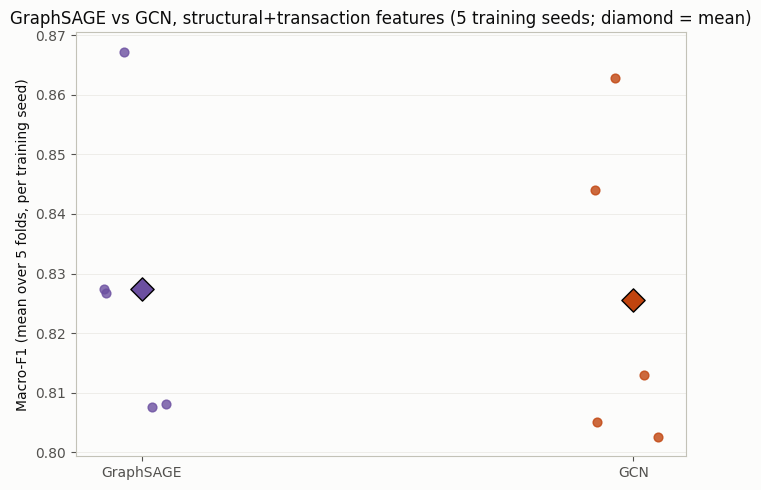


=== Multi-seed GraphSAGE/GCN (full features) experiment complete ===


In [11]:
fig, ax = plt.subplots(figsize=(7, 5))
colors = {"GraphSAGE": "#6b4fa0", "GCN": "#c1440e"}
for i, cond in enumerate(CONDITIONS):
    vals = seed_level_pivot[cond].values
    xs = np.full(len(vals), i) + np.random.default_rng(0).uniform(-0.08, 0.08, size=len(vals))
    ax.scatter(xs, vals, color=colors[cond], s=40, alpha=0.8)
    ax.scatter([i], [vals.mean()], color=colors[cond], s=140, marker="D", edgecolor="black", linewidth=1, zorder=5)
ax.set_xticks(range(len(CONDITIONS)))
ax.set_xticklabels(list(CONDITIONS.keys()), fontsize=10)
ax.set_ylabel(f"Macro-F1 (mean over {N_SPLITS} folds, per training seed)")
ax.set_title(f"GraphSAGE vs GCN, structural+transaction features ({N_SEEDS} training seeds; diamond = mean)")
ax.grid(axis="y", linewidth=0.6, alpha=0.6)
ax.set_axisbelow(True)
fig.tight_layout()
display(fig)
plt.close(fig)

print("\n=== Multi-seed GraphSAGE/GCN (full features) experiment complete ===")

## Key result tables

In [12]:
display(primary_df)

,comparison,n_seeds,mean_diff,diff_95ci_lo,diff_95ci_hi,paired_t_stat,paired_p_value,pct_seeds_graphsage_better
0,GraphSAGE - GCN (both structural+transaction_b...,5,0.0019,-0.0158,0.0196,0.3009,0.7785,0.6


## Interpretation

GraphSAGE and GCN are evaluated as conditional multi-seed stability results on one fixed graph and balanced address subset.